# 문제 정형화와 평가지표 실습: 문제를 직접 정해 보기

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week01/problem_formulation/lab/problem_formulation.ipynb)

모델보다 먼저 **다섯 칸** 을 채운다: ① 한 행은 무엇? ② 입력 X ③ 출력 y ④ 평가지표 ⑤ 기준선.

- **파트 1**: 와인: 같은 데이터로 두 문제 (품종 분류 · 알코올 도수 회귀), 정확도 · MAE · 기준선 직접 만들기
- **파트 2**: 항공 승객: 기준선 (지난달 그대로 · 작년 같은 달) vs kNN 모델
- **파트 3**: IBM AML 자금세탁 거래: 정확도의 함정, 정밀도 · 재현율, 한 행을 거래 → 계좌로
- **파트 4**: 넷플릭스 프라이즈 축소판: 사람마다 최근 별점을 숨기고 RMSE, '10% 개선' 목표

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요. 코드 칸 아래의 **예상 결과** 와 비교하면 맞았는지 바로 알 수 있습니다.

In [ ]:
import io, json, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

## 파트 1. 와인 178병: 같은 데이터, 두 문제

먼저 채점 함수 세 개를 만든다. 정답 `y_true` 와 예측 `y_pred` 를 받는다.
- 정확도 = 맞힌 개수 ÷ 전체
- MAE = 오차 절댓값의 평균
- RMSE = 오차 제곱의 평균에 루트

In [ ]:
def accuracy(y_true, y_pred):
    return None   # TODO: fraction of exact matches

def mae(y_true, y_pred):
    return None   # TODO: mean of |error|

def rmse(y_true, y_pred):
    return None   # TODO: sqrt of mean of error^2

print("accuracy:", accuracy([0, 1, 2, 2], [0, 1, 1, 2]))          # 0.75
print("MAE :", mae([0, 0, 0, 0], [1, 1, 1, 9]))                  # slide: 3
print("RMSE:", round(rmse([0, 0, 0, 0], [1, 1, 1, 9]), 2))       # slide: 4.58

**예상 결과**

```
accuracy: 0.75
MAE : 3.0
RMSE: 4.58
```

In [ ]:
wine = load_wine(as_frame=True)
df = wine.data.copy()
df["cultivar"] = wine.target
print(df.shape)
print(df["cultivar"].value_counts().sort_index())
df.head(3)

**예상 결과**

```
(178, 14)
cultivar
0    59
1    71
2    48
Name: count, dtype: int64
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   

   od280/od315_of_diluted_wines  proline  cultivar  
0                          3.92   1065.0         0  
... (2줄 더)
```

### 문제 A: 13성분 → 품종 (분류)

`X` 는 13성분 전부, `y` 는 품종. 학습 70% · 시험 30% (품종 비율을 맞춰서). **기준선** = 학습 데이터에서 가장 많은 품종을 늘 답하기.

In [ ]:
X_a = None   # TODO: all 13 measurements (drop the answer column)
y_a = None   # TODO: the cultivar column
Xtr, Xte, ytr, yte = train_test_split(X_a, y_a, test_size=0.3, stratify=y_a, random_state=0)

most_common = ytr.value_counts().idxmax()
base_pred = np.full(len(yte), most_common)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
print(f"baseline (always cultivar {most_common}): accuracy {accuracy(yte, base_pred):.0%}")
print(f"logistic regression           : accuracy {accuracy(yte, model.predict(Xte)):.0%}")

**예상 결과**

```
baseline (always cultivar 1): accuracy 39%
logistic regression           : accuracy 100%
```

### 문제 B: 같은 와인, 12성분 → 알코올 도수 (회귀)

이번엔 `y` 가 알코올 도수. **입력에서 알코올을 빼야 한다** (답을 입력에 넣으면 안 된다). 품종도 입력에서 뺀다. 같은 행으로 학습 · 시험을 나눈다. **기준선** = 학습 데이터의 평균 도수를 늘 답하기.

In [ ]:
X_b = None   # TODO: drop the answer (alcohol) and cultivar
y_b = None   # TODO: alcohol column
Xtr_b, Xte_b = X_b.loc[Xtr.index], X_b.loc[Xte.index]
ytr_b, yte_b = y_b.loc[Xtr.index], y_b.loc[Xte.index]

base_pred = np.full(len(yte_b), ytr_b.mean())
reg = make_pipeline(StandardScaler(), LinearRegression()).fit(Xtr_b, ytr_b)
print(f"baseline (always {ytr_b.mean():.2f}): MAE {mae(yte_b, base_pred):.2f}  RMSE {rmse(yte_b, base_pred):.2f}")
print(f"linear regression      : MAE {mae(yte_b, reg.predict(Xte_b)):.2f}  RMSE {rmse(yte_b, reg.predict(Xte_b)):.2f}")

**예상 결과**

```
baseline (always 13.03): MAE 0.66  RMSE 0.78
linear regression      : MAE 0.45  RMSE 0.56
```

**생각해 보기**: 문제 B 의 입력에 `alcohol` 을 그대로 두면 MAE 가 얼마가 될까? 한 번 해 보고, 그 점수가 왜 의미 없는지 말해 보자.

## 파트 2. 항공 승객: 기준선이 모델을 이길 수 있다

한 달 국제선 승객 수 (천 명), 1949~1960. 앞 10년 (120달) 으로 학습, 뒤 2년 (24달) 을 예측한다. **시간 순서대로** 나눈다.

In [ ]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
air = pd.read_csv(url)
series = air["Passengers"].values.astype(float)
N_TRAIN, W = 120, 12
print(len(series), "months;", air["Month"].iloc[0], "~", air["Month"].iloc[-1])

X = np.stack([series[i:i + W] for i in range(len(series) - W)])     # past 12 months
y = series[W:]                                                      # next month
is_train = np.arange(W, len(series)) < N_TRAIN
y_test = y[~is_train]
print(X.shape, "test months:", len(y_test))

**예상 결과**

```
144 months; 1949-01 ~ 1960-12
(132, 12) test months: 24
```

세 가지 기준선을 만든다. `X` 의 각 행은 지난 12달 (`X[:, -1]` = 지난달, `X[:, 0]` = 12달 전 = 작년 같은 달).

In [ ]:
base_mean = np.full(len(y_test), series[:N_TRAIN].mean())   # always the training-period average
base_last = None     # TODO: last month's value
base_season = None   # TODO: same month last year

mu, sd = series[:N_TRAIN].mean(), series[:N_TRAIN].std()
knn = KNeighborsRegressor(3).fit((X[is_train] - mu) / sd, (y[is_train] - mu) / sd)
pred_knn = knn.predict((X[~is_train] - mu) / sd) * sd + mu

results = {"training average": base_mean, "last month": base_last, "same month last year": base_season, "kNN model": pred_knn}
for name, pred in results.items():
    print(f"{name:22s} MAE {mae(y_test, pred):5.1f}")
plt.figure(figsize=(7, 3)); plt.bar(results.keys(), [mae(y_test, p) for p in results.values()], color=["gray", "navy", "navy", "red"])
plt.ylabel("test MAE (1000s)"); plt.xticks(fontsize=8); plt.show()

**예상 결과**

```
training average       MAE 206.3
last month             MAE  44.2
same month last year   MAE  47.6
kNN model              MAE  73.9
```

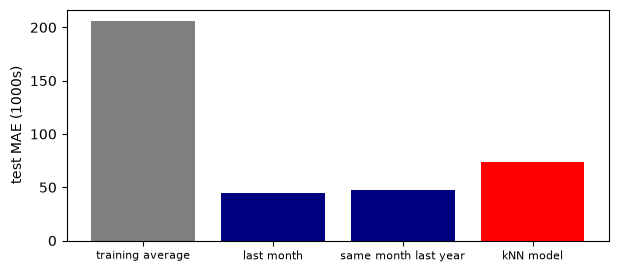

**관찰**: kNN 모델 (74) 이 '지난달 그대로' (44) 보다 못하다. 기준선을 재 보지 않았다면 몰랐을 일이다. (다음 차시 정규화 실습에서 창마다 표준화하면 이 모델이 10 까지 내려간다.)

## 파트 3. IBM AML: 자금세탁 거래 찾기

IBM 이 가상의 사람 · 회사 · 은행을 시뮬레이션해 만든 합성 거래 데이터 (Altman et al., NeurIPS 2023). 원본은 Kaggle 에 있고, 여기서는 로그인 없이 받을 수 있는 Hugging Face 사본에서 받는다.

압축 파일 약 90MB, 풀면 약 480MB. 처음엔 몇 분 걸린다.

In [ ]:
os.makedirs("data", exist_ok=True)
URL = "https://huggingface.co/datasets/eexzzm/IBM-Transactions-for-Anti-Money-Laundering-HI-Small-Trans/resolve/main/HI-Small_Trans.csv.zip"
ZIP = "data/HI-Small_Trans.csv.zip"
if not os.path.exists(ZIP):
    urllib.request.urlretrieve(URL, ZIP)
print(round(os.path.getsize(ZIP) / 1e6), "MB")

**예상 결과**

```
91 MB
```

In [ ]:
with zipfile.ZipFile(ZIP) as z:
    df = pd.read_csv(z.open("HI-Small_Trans.csv"))
print(df.shape)
print(df.dtypes)
df.head(3)

**예상 결과**

```
(5078345, 11)
Timestamp                 str
From Bank               int64
Account                   str
To Bank                 int64
Account.1                 str
Amount Received       float64
Receiving Currency        str
Amount Paid           float64
Payment Currency          str
Payment Format            str
Is Laundering           int64
dtype: object
          Timestamp  From Bank    Account  To Bank  Account.1  \
0  2022/09/01 00:20         10  8000EBD30       10  8000EBD30   
1  2022/09/01 00:20       3208  8000F4580        1  8000F5340   
2  2022/09/01 00:00       3209  8000F4670     3209  8000F4670   

... (9줄 더)
```

### ① 한 행 = 거래 한 건

출력 `y` 는 `Is Laundering` (0/1). 세탁 거래는 몇 건, 몇 % 일까? 그리고 **모든 거래에 '정상' (0)** 이라고 답하면 정확도는?

In [ ]:
y = df["Is Laundering"].values
print("transactions:", len(y), "  laundering:", y.sum(), f"({y.mean():.3%})")

all_normal = None   # TODO: predict 0 for every transaction
print(f"'always normal' accuracy: {accuracy(y, all_normal):.3%}")

**예상 결과**

```
transactions: 5078345   laundering: 5177 (0.102%)
'always normal' accuracy: 99.898%
```

정확도가 매우 높지만 세탁을 하나도 못 잡는다. 결제 형식별로 세탁 비율을 보고, **가장 비율이 높은 형식이면 '세탁'** 이라고 답하는 규칙 하나를 만들어 보자.

In [ ]:
by_format = df.groupby("Payment Format")["Is Laundering"].agg(["mean", "sum", "size"]).sort_values("mean", ascending=False)
print(by_format)
fmt = by_format.index[0]
rule = None   # TODO: 1 if the payment format is fmt, else 0
print(f"rule '{fmt} -> laundering' accuracy: {accuracy(y, rule):.3%}")

**예상 결과**

```
                    mean   sum     size
Payment Format                         
ACH             0.007462  4483   600797
Bitcoin         0.000383    56   146091
Cash            0.000220   108   490891
Cheque          0.000174   324  1864331
Credit Card     0.000156   206  1323324
Reinvestment    0.000000     0   481056
Wire            0.000000     0   171855
rule 'ACH -> laundering' accuracy: 88.244%
```

### 정밀도와 재현율: 세는 법을 바꾼다

- **재현율** = 잡았다 ÷ 실제 세탁 전부 (실제 세탁 중 몇 개를 잡았나)
- **정밀도** = 잡았다 ÷ '세탁' 이라고 한 것 전부 (찍은 것 중 진짜는 몇 개)

(2주차 정밀도와 재현율에서 자세히 다룬다.)

In [ ]:
def precision_recall(y_true, y_pred):
    tp = np.sum((y_pred == 1) & (y_true == 1))     # caught
    fp = np.sum((y_pred == 1) & (y_true == 0))     # false alarm
    fn = np.sum((y_pred == 0) & (y_true == 1))     # missed
    precision = None   # TODO: caught / everything we called laundering
    recall = None      # TODO: caught / all real laundering
    return tp, fp, fn, precision, recall

for name, pred in [("always normal", all_normal), (f"rule: {fmt}", rule)]:
    tp, fp, fn, p, r = precision_recall(y, pred)
    print(f"{name:16s} caught {tp:5d}  false alarms {fp:7d}  missed {fn:5d}  precision {p:.1%}  recall {r:.1%}")

**예상 결과**

```
always normal    caught     0  false alarms       0  missed  5177  precision 0.0%  recall 0.0%
rule: ACH        caught  4483  false alarms  596314  missed   694  precision 0.7%  recall 86.6%
```

### ② 한 행 = 계좌 하나

은행이 실제로 하는 일은 '이 계좌를 조사할까?' 다. 보낸 쪽 계좌 (`From Bank` + `Account`) 하나를 한 행으로, **세탁 거래를 한 번이라도 보냈으면 1** 로 정해 보자.

In [ ]:
sender = df["From Bank"].astype(str) + "_" + df["Account"].astype(str)
account_y = None   # TODO: per sender account, 1 if any of its transactions is laundering (groupby + max)
print("accounts:", len(account_y), "  laundering accounts:", account_y.sum(), f"({account_y.mean():.2%})")
print(f"transaction-level rate {y.mean():.3%}  ->  account-level rate {account_y.mean():.2%}")

**예상 결과**

```
accounts: 496999   laundering accounts: 3376 (0.68%)
transaction-level rate 0.102%  ->  account-level rate 0.68%
```

**관찰**: 같은 파일인데 한 행을 무엇으로 정하느냐에 따라 세탁 비율이 달라진다. 이 데이터를 쓴 논문들마다 '세탁 비율' 이 다르게 적힌 이유다.

**생각해 보기**: 시험 데이터는 어떻게 나눠야 할까? `Timestamp` 열을 보고, 무작위로 섞으면 왜 안 되는지 말해 보자.

## 파트 4. 넷플릭스 프라이즈 축소판: 영화 별점

넷플릭스 프라이즈 (2006) 는 '사용자마다 **가장 최근** 별점을 숨기고, RMSE 로 채점, 기준선보다 10% 나으면 우승' 이었다. 같은 규칙을 MovieLens (610명 · 별점 10만 개) 로 작게 해 보자.

In [ ]:
URL = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/ml-latest-small.zip"):
    urllib.request.urlretrieve(URL, "data/ml-latest-small.zip")
with zipfile.ZipFile("data/ml-latest-small.zip") as z:
    ratings = pd.read_csv(z.open("ml-latest-small/ratings.csv"))
print(ratings.shape, "users", ratings["userId"].nunique(), "movies", ratings["movieId"].nunique())

# hide each user's most recent 10% of ratings (like the Netflix Prize qualifying set)
ratings = ratings.sort_values(["userId", "timestamp"])
rank = ratings.groupby("userId").cumcount(ascending=False)            # 0 = newest
n_user = ratings.groupby("userId")["rating"].transform("size")
hidden = rank < np.maximum(1, (n_user * 0.1).astype(int))
train, test = ratings[~hidden], ratings[hidden]
print("train", len(train), "hidden test", len(test))

**예상 결과**

```
(100836, 4) users 610 movies 9724
train 91018 hidden test 9818
```

세 가지 예측의 RMSE 를 비교한다.
- 기준선 1: 늘 전체 평균 별점
- 기준선 2: 영화마다 평균 별점 (넷플릭스 이전의 단순한 방법)
- 모델: 평균 + 사용자 치우침 + 영화 치우침 (후하게 주는 사람, 다들 좋아하는 영화)

그리고 '영화 평균보다 10% 나은가?' 를 확인한다.

In [ ]:
def fit_biases(train, reg=5.0):
    """Global mean + movie bias + user bias, shrunk toward 0 for movies/users with few ratings"""
    mu = train["rating"].mean()
    r = train.assign(res=train["rating"] - mu)
    b_movie = r.groupby("movieId")["res"].agg(lambda v: v.sum() / (len(v) + reg))
    r = r.assign(res=r["res"] - r["movieId"].map(b_movie))
    b_user = r.groupby("userId")["res"].agg(lambda v: v.sum() / (len(v) + reg))
    return mu, b_user, b_movie

mu, b_user, b_movie = fit_biases(train)
movie_mean = train.groupby("movieId")["rating"].mean()
preds = {"global mean": np.full(len(test), mu),
         "movie mean": test["movieId"].map(movie_mean).fillna(mu).values,
         "mean + user + movie bias": (mu + test["userId"].map(b_user).fillna(0) + test["movieId"].map(b_movie).fillna(0)).clip(0.5, 5).values}
scores = None   # TODO: RMSE of each prediction (use your rmse function)
for k, v in scores.items():
    print(f"{k:26s} RMSE {v:.4f}")
goal = scores["movie mean"] * 0.9
print(f"10% better than movie mean = {goal:.4f} -> reached: {scores['mean + user + movie bias'] < goal}")

**예상 결과**

```
global mean                RMSE 1.0753
movie mean                 RMSE 1.0209
mean + user + movie bias   RMSE 0.8904
10% better than movie mean = 0.9188 -> reached: True
```

**관찰**: '영화마다 평균' 은 전체 평균보다 조금 낫다. 여기에 사람마다 후하게 · 짜게 주는 치우침을 더하면 RMSE 가 크게 내려가 '10% 개선' 을 넘긴다. 진짜 넷플릭스 데이터에서는 기준선 (Cinematch) 이 훨씬 강해서, 우승 팀은 100개가 넘는 모델을 섞어 3년 만에 10% 를 넘겼다.

**확인 질문**
1. 파트 1 문제 B 에서 입력에 `alcohol` 을 남기면 MAE 는? 그 점수가 의미 없는 이유는?
2. 파트 2 에서 kNN 이 '지난달 그대로' 에 진 이유는 무엇일까? (힌트: 학습 기간 최댓값과 시험 기간 값을 비교해 보자)
3. 파트 3 에서 정확도 · 정밀도 · 재현율 중 은행이 가장 중요하게 볼 것은? 놓친 세탁 한 건과 헛짚은 정상 고객 한 명의 손해를 비교해 말해 보자.
4. 파트 3 에서 '전부 세탁' 이라고 답하면 재현율과 정밀도는 각각 얼마가 될까?
5. 파트 4 에서 숨길 별점을 '사람마다 가장 최근' 이 아니라 무작위로 고르면 RMSE 가 어떻게 바뀔까? 어느 쪽이 실제 서비스와 닮았을까?

데이터 출처: UCI Wine (Aeberhard & Forina, 1991) · Box & Jenkins (1976) 항공 승객 · IBM Transactions for Anti Money Laundering (Altman et al., NeurIPS 2023, Kaggle) · MovieLens (Harper & Konstan, 2015) · Netflix Prize (Bennett & Lanning, 2007).